# 8. Fano's inequality

**Cover and Thomas, Section 2.10.**

We observe $Y$ and want to guess $X$. Any guess is a function
$\hat X = g(Y)$, so $X \to Y \to \hat X$ is a Markov chain. Let
$P_e = \Pr\{\hat X \neq X\}$.

**Theorem 2.10.1 (Fano).**
$$H(P_e) + P_e \log |\mathcal X| \;\ge\; H(X \mid \hat X) \;\ge\; H(X \mid Y).$$

Weaker but often convenient forms:
$$1 + P_e \log|\mathcal X| \ge H(X\mid Y), \qquad
P_e \ge \frac{H(X \mid Y) - 1}{\log |\mathcal X|} .$$

**Corollary (sharper).** If the guess takes values in $\mathcal X$ itself,
$$H(P_e) + P_e \log(|\mathcal X| - 1) \;\ge\; H(X\mid Y).$$

Read it backwards: **if $H(X\mid Y)$ is large, no guessing rule can have a
small error probability.** This is the inequality that gives the converse to
the channel coding theorem in Chapter 7.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import infotools as it

it.setup_plot_style()
rng = np.random.default_rng(8)

## 8.1 The best possible guess

Given the joint table `P[i, j]` $= p(x_i, y_j)$, the guess with the smallest
error probability is the one that picks, for each observed $y$, the value of
$x$ with the largest $p(x, y)$. Its error probability is

$$P_e^{\min} = 1 - \sum_y \max_x p(x,y).$$

No rule can do better, so if even this one has a large error, every rule does.

In [2]:
def best_guess(P):
    """The MAP rule: for each column y, the row x with the largest p(x, y)."""
    return np.argmax(np.asarray(P, dtype=float), axis=0)


def error_probability(P):
    """Error probability of the best guess."""
    P = np.asarray(P, dtype=float)
    return float(1.0 - P.max(axis=0).sum())


# a small example: a bit sent through a noisy channel
P = np.array([[0.45, 0.05],
              [0.10, 0.40]])
it.show_table(P)
print()
print("best guess for each y:", best_guess(P), " (row index)")
print(f"P_e      = {error_probability(P):.6f}")
print(f"H(X|Y)   = {it.cond_entropy_X_given_Y(P):.6f} bits")

X\Y           1        2       p(x)
    1    0.4500   0.0500     0.5000
    2    0.1000   0.4000     0.5000
 p(y)    0.5500   0.4500     1.0000

best guess for each y: [0 1]  (row index)
P_e      = 0.150000
H(X|Y)   = 0.602687 bits


## 8.2 The inequality on this example

In [3]:
def fano_bound(Pe, m, sharp=True):
    """The right-hand side of Fano: H(Pe) + Pe log2(m-1), or with log2(m)."""
    size = (m - 1) if sharp else m
    extra = Pe * np.log2(size) if size > 1 else 0.0      # log2(1) = 0 when m = 2
    return float(it.binary_entropy(Pe)) + extra


m = P.shape[0]
Pe = error_probability(P)
H_X_g_Y = it.cond_entropy_X_given_Y(P)

print(f"H(X|Y)                          = {H_X_g_Y:.6f} bits")
print(f"H(Pe) + Pe log2(|X| - 1)        = {fano_bound(Pe, m, sharp=True):.6f}")
print(f"H(Pe) + Pe log2(|X|)            = {fano_bound(Pe, m, sharp=False):.6f}")
print(f"1 + Pe log2(|X|)                = {1 + Pe*np.log2(m):.6f}")
print()
print(f"lower bound on the error:  (H(X|Y) - 1)/log2(|X|) = {(H_X_g_Y - 1)/np.log2(m):.6f}")
print(f"actual Pe                                        = {Pe:.6f}")

it.check("Fano (sharp form)", fano_bound(Pe, m, True) >= H_X_g_Y - 1e-12)
it.check("Fano (weak form)", 1 + Pe*np.log2(m) >= H_X_g_Y - 1e-12)
it.check("lower bound on Pe", Pe >= (H_X_g_Y - 1)/np.log2(m) - 1e-12)

print("\nThe lower bound came out negative here, which is true but says nothing:")
print("with only two symbols and a fairly good channel, Fano does not force any")
print("error at all. The bound becomes informative once H(X|Y) exceeds 1 bit.")

H(X|Y)                          = 0.602687 bits
H(Pe) + Pe log2(|X| - 1)        = 0.609840
H(Pe) + Pe log2(|X|)            = 0.759840
1 + Pe log2(|X|)                = 1.150000

lower bound on the error:  (H(X|Y) - 1)/log2(|X|) = -0.397313
actual Pe                                        = 0.150000
[PASS] Fano (sharp form)
[PASS] Fano (weak form)
[PASS] lower bound on Pe

The lower bound came out negative here, which is true but says nothing:
with only two symbols and a fairly good channel, Fano does not force any
error at all. The bound becomes informative once H(X|Y) exceeds 1 bit.


## 8.3 The whole Fano region

Generate many random joint distributions with the same alphabet size, compute
$(P_e, H(X\mid Y))$ for each, and plot the cloud against the bound. Every
point must lie on or below the curve $H(P_e) + P_e \log(m-1)$.

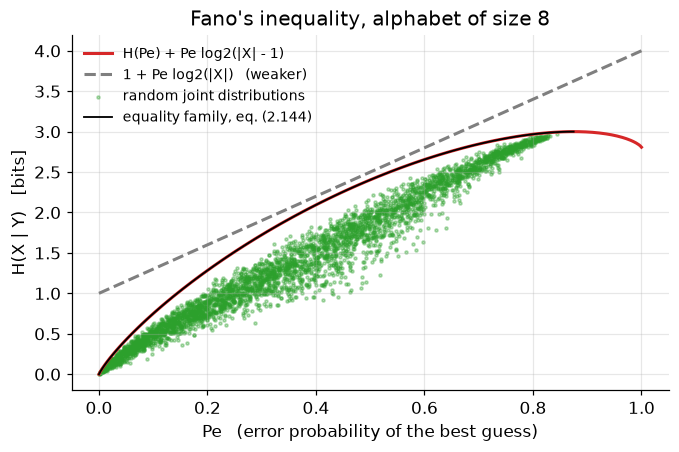

[PASS] all 4000 points satisfy the sharp Fano bound


True

In [4]:
m = 8                                   # <-- size of the alphabet of X
n_points = 4000

points_Pe, points_H = [], []
for _ in range(n_points):
    ny = int(rng.integers(2, 9))
    Q = it.random_joint(m, ny, rng)
    # a mix of nearly deterministic and nearly independent tables, for variety
    Q = Q ** rng.uniform(0.3, 6.0)
    Q = Q / Q.sum()
    points_Pe.append(error_probability(Q))
    points_H.append(it.cond_entropy_X_given_Y(Q))

points_Pe = np.array(points_Pe)
points_H = np.array(points_H)

# the sharpness family of equation (2.144): X guessed with no help from Y
sharp_Pe = np.linspace(0, 1 - 1/m, 300)
sharp_H = it.binary_entropy(sharp_Pe) + sharp_Pe * np.log2(m - 1)

pe_grid = np.linspace(0, 1, 400)
plt.plot(pe_grid, it.binary_entropy(pe_grid) + pe_grid*np.log2(m - 1),
         color=it.COLORS["D"], label="H(Pe) + Pe log2(|X| - 1)")
plt.plot(pe_grid, 1 + pe_grid*np.log2(m), "--", color=it.COLORS["bound"],
         label="1 + Pe log2(|X|)   (weaker)")
plt.scatter(points_Pe, points_H, s=4, alpha=0.35, color=it.COLORS["I"],
            label="random joint distributions")
plt.plot(sharp_Pe, sharp_H, color="black", linewidth=1.2,
         label="equality family, eq. (2.144)")
plt.xlabel("Pe   (error probability of the best guess)")
plt.ylabel("H(X | Y)   [bits]")
plt.title(f"Fano's inequality, alphabet of size {m}")
plt.legend(fontsize=9, loc="upper left")
plt.show()

it.check(f"all {n_points} points satisfy the sharp Fano bound",
         np.all(points_H <= it.binary_entropy(points_Pe)
                + points_Pe*np.log2(m - 1) + 1e-9))

## 8.4 The bound is sharp

The remark after the theorem: with no knowledge of $Y$, the best guess is the
most likely value, and the distribution

$$(p_1, \dots, p_m) = \left(1 - P_e, \frac{P_e}{m-1}, \dots, \frac{P_e}{m-1}\right)$$

attains equality in $H(P_e) + P_e \log(m-1) \ge H(X)$.

In [5]:
print(f"{'Pe':>8s} {'H(X)':>12s} {'H(Pe) + Pe log2(m-1)':>24s} {'gap':>12s}")
for Pe_target in [0.0, 0.1, 0.3, 0.5, 0.7, 1 - 1/m]:
    p = np.full(m, Pe_target / (m - 1))
    p[0] = 1 - Pe_target
    H_p = it.entropy(p)
    bound = float(it.binary_entropy(Pe_target)) + Pe_target*np.log2(m - 1)
    print(f"{Pe_target:>8.3f} {H_p:>12.6f} {bound:>24.6f} {bound - H_p:>12.2e}")

it.check("equality holds for the family of equation (2.144)",
         all(abs(it.entropy(np.concatenate([[1 - t], np.full(m - 1, t/(m - 1))])) -
                 (float(it.binary_entropy(t)) + t*np.log2(m - 1))) < 1e-12
             for t in [0.1, 0.3, 0.5, 0.7]))

      Pe         H(X)     H(Pe) + Pe log2(m-1)          gap
   0.000     0.000000                 0.000000     0.00e+00
   0.100     0.749731                 0.749731     0.00e+00
   0.300     1.723497                 1.723497     0.00e+00
   0.500     2.403677                 2.403677     0.00e+00
   0.700     2.846439                 2.846439     0.00e+00
   0.875     3.000000                 3.000000     0.00e+00
[PASS] equality holds for the family of equation (2.144)


True

## 8.5 Simulating the guessing game

Draw pairs $(X, Y)$, apply the best guess to each observed $Y$, and count how
often it is wrong. The empirical error rate should approach $P_e$, and the
Fano bound should hold for the empirical numbers too.

In [6]:
P = np.array([[0.45, 0.05],
              [0.10, 0.40]])
nx, ny = P.shape
guess = best_guess(P)

n = 100_000
flat = rng.choice(nx*ny, size=n, p=P.ravel())
x_samples, y_samples = np.divmod(flat, ny)
x_hat = guess[y_samples]

empirical_error = float(np.mean(x_hat != x_samples))
print(f"empirical error rate = {empirical_error:.5f}")
print(f"theoretical Pe       = {error_probability(P):.5f}")

# the same quantity from the table of (X, X_hat)
T = np.zeros((nx, nx))
for a, b in zip(x_samples, x_hat):
    T[a, b] += 1
T = T / n

print()
print(f"H(X | X_hat) = {it.cond_entropy_X_given_Y(T):.6f} bits")
print(f"H(X | Y)     = {it.cond_entropy_X_given_Y(P):.6f} bits")
it.check("H(X | X_hat) >= H(X | Y), the second inequality of Theorem 2.10.1",
         it.cond_entropy_X_given_Y(T) >= it.cond_entropy_X_given_Y(P) - 5e-3)

empirical error rate = 0.15098
theoretical Pe       = 0.15000

H(X | X_hat) = 0.605256 bits
H(X | Y)     = 0.602687 bits
[PASS] H(X | X_hat) >= H(X | Y), the second inequality of Theorem 2.10.1


True

## 8.6 How much noise can a guesser tolerate?

Take $X$ uniform on $m$ symbols, sent through a channel that delivers the
correct symbol with probability $1 - \varepsilon$ and otherwise a uniformly
chosen wrong one. As $\varepsilon$ grows, $H(X\mid Y)$ grows and the Fano
bound forces the error probability up.

In [7]:
def symmetric_channel_joint(m, eps):
    """X uniform on m symbols; the channel is correct with probability 1 - eps."""
    W = np.full((m, m), eps / (m - 1))
    np.fill_diagonal(W, 1 - eps)
    return W / m


def show_fano(m=8, eps=0.3):
    P = symmetric_channel_joint(m, eps)
    Pe = error_probability(P)
    Hc = it.cond_entropy_X_given_Y(P)
    bound = float(it.binary_entropy(Pe)) + Pe*np.log2(m - 1)
    lower = (Hc - 1) / np.log2(m)

    eps_grid = np.linspace(0, 1 - 1/m, 200)
    Pe_curve = [error_probability(symmetric_channel_joint(m, e)) for e in eps_grid]
    H_curve = [it.cond_entropy_X_given_Y(symmetric_channel_joint(m, e)) for e in eps_grid]

    plt.figure()
    plt.plot(Pe_curve, H_curve, color=it.COLORS["I"], label="this channel family")
    pe_grid = np.linspace(0, 1, 300)
    plt.plot(pe_grid, it.binary_entropy(pe_grid) + pe_grid*np.log2(m - 1),
             color=it.COLORS["D"], label="Fano bound")
    plt.plot([Pe], [Hc], "o", color="black", markersize=9)
    plt.xlabel("Pe")
    plt.ylabel("H(X | Y)   [bits]")
    plt.title(f"m = {m}, eps = {eps:.2f}:  Pe = {Pe:.3f},  H(X|Y) = {Hc:.3f},  "
              f"Fano gives Pe >= {max(lower, 0):.3f}")
    plt.legend(fontsize=9)
    plt.show()


try:
    from ipywidgets import interact, FloatSlider, IntSlider
    interact(show_fano,
             m=IntSlider(min=2, max=16, step=1, value=8),
             eps=FloatSlider(min=0.0, max=0.9, step=0.02, value=0.3))
except ImportError:
    show_fano(8, 0.3)
    print("(install ipywidgets to get the sliders)")

interactive(children=(IntSlider(value=8, description='m', max=16, min=2), FloatSlider(value=0.3, description='…

## 8.7 Lemma 2.10.1: the probability of a collision

If $X$ and $X'$ are independent and identically distributed,

$$\Pr\{X = X'\} = \sum_x p^2(x) \;\ge\; 2^{-H(X)},$$

with equality if and only if $X$ is uniform. The proof is Jensen's inequality
applied to $2^{\,t}$.

In [8]:
worst = np.inf
for _ in range(20_000):
    k = int(rng.integers(2, 10))
    p = it.random_pmf(k, rng)
    collision = float(np.sum(p**2))
    worst = min(worst, collision - 2.0**(-it.entropy(p)))

it.check("Pr(X = X') >= 2^{-H(X)} on 20000 random distributions", worst >= -1e-12,
         f"smallest slack seen: {worst:.3e}")

for k in [2, 4, 8]:
    u = np.ones(k) / k
    print(f"uniform on {k:2d} outcomes:  Pr(X = X') = {np.sum(u**2):.6f},"
          f"  2^-H = {2.0**(-it.entropy(u)):.6f}   (equal)")

[PASS] Pr(X = X') >= 2^{-H(X)} on 20000 random distributions   smallest slack seen: 3.332e-06
uniform on  2 outcomes:  Pr(X = X') = 0.500000,  2^-H = 0.500000   (equal)
uniform on  4 outcomes:  Pr(X = X') = 0.250000,  2^-H = 0.250000   (equal)
uniform on  8 outcomes:  Pr(X = X') = 0.125000,  2^-H = 0.125000   (equal)


## 8.8 Summary of the chapter, as one picture

The quantities of Chapter 2 for a single channel, side by side.

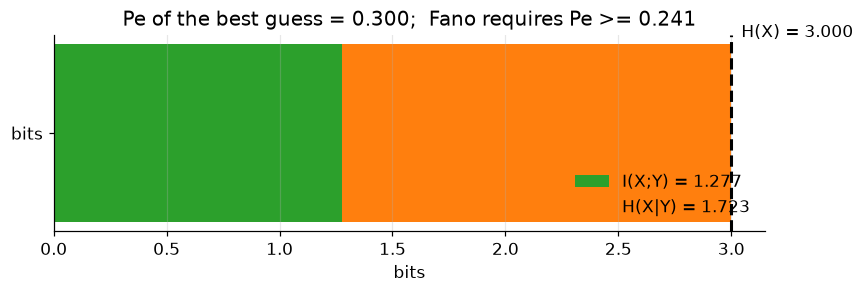

In [9]:
P = symmetric_channel_joint(8, 0.3)
H_X = it.entropy(it.marginal_X(P))
H_X_g_Y = it.cond_entropy_X_given_Y(P)
I_XY = it.mutual_information(P)
Pe = error_probability(P)

fig, ax = plt.subplots(figsize=(8.0, 2.8))
ax.barh(["bits"], [I_XY], color=it.COLORS["I"], label=f"I(X;Y) = {I_XY:.3f}")
ax.barh(["bits"], [H_X_g_Y], left=[I_XY], color=it.COLORS["cond"],
        label=f"H(X|Y) = {H_X_g_Y:.3f}")
ax.axvline(H_X, color="black", linestyle="--")
ax.text(H_X, 0.45, f"  H(X) = {H_X:.3f}", va="center")
ax.set_xlabel("bits")
ax.set_title(f"Pe of the best guess = {Pe:.3f};  Fano requires Pe >= "
             f"{max((H_X_g_Y - 1)/np.log2(8), 0):.3f}")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()